## Data source

The data comes from the French government's directory of organizations supporting women affected by violence.

Source: https://annuaire.arretonslesviolences.gouv.fr/

I will focus on four departments: Rhône (69), Isère (38), Savoie (73) and Haute-Savoie (74).

In [1]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt

In [2]:
url = "https://annuaire.arretonslesviolences.gouv.fr/" 
response = requests.get(url)
print(response.status_code)

200


In [3]:
soup = BeautifulSoup(response.text, "html.parser")
print (soup.title)

<title>Trouver une structure — Annuaire Arrêtons les violences</title>


In [4]:
print (soup.find_all("h3")[:5])

[]


In [5]:
url_search = "https://annuaire.arretonslesviolences.gouv.fr/search"

params = {
    "q": "Lyon",
    "lat": 45.764,
    "lng": 4.8357,
    "label": "Lyon",
    "page": 1
}

response = requests.get(url_search, params=params, timeout=15)
soup = BeautifulSoup(response.text, "html.parser")

print(response.status_code)
print(soup.find_all("h3")[:5])

200
[<h3 class="fr-h6 fr-mb-0" id="_R_2n5fiv95uedb_">Ça Démenage</h3>, <h3 class="fr-h6 fr-mb-0" id="_R_4n5fiv95uedb_">Femmes Contre Les Intégrismes (fci)</h3>, <h3 class="fr-h6 fr-mb-0" id="_R_6n5fiv95uedb_">Cidff Rhône - Arcalpin</h3>, <h3 class="fr-h6 fr-mb-0" id="_R_8n5fiv95uedb_">Cidff Rhône-Arc Alpin Interdépartemental, Lyon</h3>, <h3 class="fr-h6 fr-mb-0" id="_R_an5fiv95uedb_">Filactions</h3>]


In [6]:
# Get the association names
names = []

for h3 in soup.find_all("h3"):
    names.append(h3.get_text(strip=True))

print(names)
print("Number of results:", len(names))

['Ça Démenage', 'Femmes Contre Les Intégrismes (fci)', 'Cidff Rhône - Arcalpin', 'Cidff Rhône-Arc Alpin Interdépartemental, Lyon', 'Filactions', 'Femmes Solidaires Lyon', 'Au Tambour !', 'Mouvement Du Nid Rhône', 'Le Planning Familial - 69', 'Le Mas Info Droits Victimes']
Number of results: 10


In [7]:
first_h3 = soup.find("h3")
card = first_h3.parent.parent

print(card.prettify()[:3000])

<div class="fr-px-8v fr-py-6v grid gap-4 border border-default-grey bg-default-grey">
 <div class="grid grid-cols-[minmax(0,1fr)_auto] items-start gap-x-2 gap-y-1">
  <h3 class="fr-h6 fr-mb-0" id="_R_2n5fiv95uedb_">
   Ça Démenage
  </h3>
  <p class="fr-badge fr-badge--sm fr-badge--no-icon fr-badge--purple-glycine normal-case" id="fr-badge-_R_j2n5fiv95uedb_">
   <span class="fr-sr-only">
    Distance :
   </span>
   428 m
  </p>
  <p class="fr-hint-text fr-mb-0 col-span-full font-normal">
   Réseau :
   <!-- -->
   Fédération Nationale Solidarités Femmes
  </p>
 </div>
 <dl class="fr-raw-list grid gap-4">
  <dt class="fr-sr-only">
   Adresse e-mail
  </dt>
  <dd class="grid grid-cols-[auto_minmax(0,1fr)] items-start gap-x-2">
   <span aria-hidden="true" class="fr-icon-mail-line text-action-high-blue-france">
   </span>
   <div class="min-w-0">
    <a href="mailto:contact@cademenage.org">
     contact@cademenage.org
    </a>
   </div>
  </dd>
  <dt class="fr-sr-only">
   Site web
  </dt

In [8]:
# Violence types listed on the first card
violence_types = []

for tag in card.find_all("p", class_="fr-tag"):
    violence_types.append(tag.get_text(strip=True))

print(violence_types)

['Violence au sein du couple']


In [9]:
associations = []

for h3 in soup.find_all("h3"):
    card = h3.parent.parent
    name = h3.get_text(strip=True)

    violence_types = []
    for tag in card.find_all("p", class_="fr-tag"):
        violence_types.append(tag.get_text(strip=True))

    network_tag = card.find("p", class_="fr-hint-text")

    if network_tag:
        network = network_tag.get_text(" ", strip=True).replace("Réseau :", "").strip()
    else:
        network = None
    contacts = {}

    for dt in card.find_all("dt"):
        dd = dt.find_next_sibling("dd")

        if dd:
            label = dt.get_text(strip=True)
            value = dd.get_text(" ", strip=True)
            contacts[label] = value

    associations.append({
        "name": name,
        "network": network,
        "violence_types": violence_types
    })

df_lyon = pd.DataFrame(associations)
df_lyon.head()

,name,network,violence_types
0,Ça Démenage,Fédération Nationale Solidarités Femmes,[Violence au sein du couple]
1,Femmes Contre Les Intégrismes (fci),Fédération Nationale Solidarités Femmes,[Violence au sein du couple]
2,Cidff Rhône - Arcalpin,Fédération Nationale des CIDFF,"[Violence au sein du couple, Viol ou agression..."
3,"Cidff Rhône-Arc Alpin Interdépartemental, Lyon",Fédération Nationale des CIDFF,"[Violence au sein du couple, Viol ou agression..."
4,Filactions,Fédération Nationale Solidarités Femmes,[Violence au sein du couple]


In [10]:
card = soup.find("h3").parent.parent

for dt in card.find_all("dt"):
    dd = dt.find_next_sibling("dd")
    print(dt.get_text(strip=True), ":", dd.get_text(" ", strip=True))

Adresse e-mail : contact@cademenage.org
Site web : cademenage.org
Types de violence : Violence au sein du couple


In [11]:
# Contact details for the first association
contacts = {}

for dt in card.find_all("dt"):
    dd = dt.find_next_sibling("dd")

    if dd:
        label = dt.get_text(strip=True)
        value = dd.get_text(" ", strip=True)
        contacts[label] = value

print(contacts)

{'Adresse e-mail': 'contact@cademenage.org', 'Site web': 'cademenage.org', 'Types de violence': 'Violence au sein du couple'}


In [12]:
# Collect all result pages for Lyon
all_associations = []

for page in range(1, 4):
    params["page"] = page

    response = requests.get(url_search, params=params, timeout=15)
    soup_page = BeautifulSoup(response.text, "html.parser")

    for h3 in soup_page.find_all("h3"):
        card = h3.parent.parent

        name = h3.get_text(strip=True)

        network_tag = card.find("p", class_="fr-hint-text")
        network = (
            network_tag.get_text(" ", strip=True).replace("Réseau :", "").strip()
            if network_tag else None
        )

        violence_types = [
            tag.get_text(strip=True)
            for tag in card.find_all("p", class_="fr-tag")
        ]

        contacts = {}
        for dt in card.find_all("dt"):
            dd = dt.find_next_sibling("dd")
            if dd:
                contacts[dt.get_text(strip=True)] = dd.get_text(" ", strip=True)

        all_associations.append({
            "name": name,
            "network": network,
            "email": contacts.get("Adresse e-mail"),
            "phone": contacts.get("Téléphone"),
            "website": contacts.get("Site web"),
            "violence_types": violence_types,
            "search_city": "Lyon"
        })

df_lyon = pd.DataFrame(all_associations)

print("Total rows:", len(df_lyon))
display(df_lyon.head())

Total rows: 25


,name,network,email,phone,website,violence_types,search_city
0,Ça Démenage,Fédération Nationale Solidarités Femmes,contact@cademenage.org,NaN,cademenage.org,[Violence au sein du couple],Lyon
1,Femmes Contre Les Intégrismes (fci),Fédération Nationale Solidarités Femmes,fcilyon@yahoo.fr,+33 6 38 73 59 17,fci-asso.org,[Violence au sein du couple],Lyon
2,Cidff Rhône - Arcalpin,Fédération Nationale des CIDFF,cidff.contact@cidff-id.fr,+33 9 78 08 47 48,rhonearcalpin-interdepartemental.cidff.info,"[Violence au sein du couple, Viol ou agression...",Lyon
3,"Cidff Rhône-Arc Alpin Interdépartemental, Lyon",Fédération Nationale des CIDFF,cidff.contact@cidff-id.fr,+33 9 78 08 47 48,rhonearcalpin-interdepartemental.cidff.info,"[Violence au sein du couple, Viol ou agression...",Lyon
4,Filactions,Fédération Nationale Solidarités Femmes,association@filactions.org,+33 4 78 30 63 50,filactions.org,[Violence au sein du couple],Lyon


In [13]:
# Check duplicate names and emails
print("Duplicate names:", df_lyon["name"].duplicated().sum())
print("Duplicate emails:", df_lyon["email"].dropna().duplicated().sum())

display(
    df_lyon[df_lyon["email"].duplicated(keep=False) & df_lyon["email"].notna()]
    .sort_values("email")
)

Duplicate names: 1
Duplicate emails: 2


,name,network,email,phone,website,violence_types,search_city
2,Cidff Rhône - Arcalpin,Fédération Nationale des CIDFF,cidff.contact@cidff-id.fr,+33 9 78 08 47 48,rhonearcalpin-interdepartemental.cidff.info,"[Violence au sein du couple, Viol ou agression...",Lyon
3,"Cidff Rhône-Arc Alpin Interdépartemental, Lyon",Fédération Nationale des CIDFF,cidff.contact@cidff-id.fr,+33 9 78 08 47 48,rhonearcalpin-interdepartemental.cidff.info,"[Violence au sein du couple, Viol ou agression...",Lyon
10,Viffilavi France Victimes 69,France Victimes,viffilavi@viffil.com,+33 4 78 85 76 47,viffil.com,"[Violence au sein du couple, Viol ou agression...",Lyon
11,Viffil Sos Femmes,Fédération Nationale Solidarités Femmes,viffilavi@viffil.com,+33 4 78 85 76 47,viffil.com,[Violence au sein du couple],Lyon


In [14]:
# Remove duplicates identified through field knowledge
df_lyon_clean = df_lyon.drop(index=[3, 11]).reset_index(drop=True)

print("Before cleaning:", len(df_lyon))
print("After cleaning:", len(df_lyon_clean))

Before cleaning: 25
After cleaning: 23


In [15]:
# Save cleaned Lyon data
from pathlib import Path

Path("data/processed").mkdir(parents=True, exist_ok=True)

df_lyon_clean.to_csv(
    "data/processed/lyon_associations.csv",
    index=False
)

In [16]:
# Search associations in Grenoble
params = {
    "q": "Grenoble",
    "lat": 45.1885,
    "lng": 5.7245,
    "label": "Grenoble",
    "page": 1
}

response = requests.get(url_search, params=params, timeout=15)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

print("Results on page 1:", len(soup.find_all("h3")))

Results on page 1: 10


In [17]:
# Collect associations in Grenoble
grenoble_results = []

for page in range(1, 11):
    params["page"] = page

    response = requests.get(url_search, params=params, timeout=15)
    response.raise_for_status()
    soup_page = BeautifulSoup(response.text, "html.parser")

    cards = soup_page.find_all("h3")

    if not cards:
        break

    for h3 in cards:
        card = h3.parent.parent

        network_tag = card.find("p", class_="fr-hint-text")
        network = (
            network_tag.get_text(" ", strip=True).replace("Réseau :", "").strip()
            if network_tag else None
        )

        violence_types = [
            tag.get_text(strip=True)
            for tag in card.find_all("p", class_="fr-tag")
        ]

        contacts = {}
        for dt in card.find_all("dt"):
            dd = dt.find_next_sibling("dd")
            if dd:
                contacts[dt.get_text(strip=True)] = dd.get_text(" ", strip=True)

        grenoble_results.append({
            "name": h3.get_text(strip=True),
            "network": network,
            "email": contacts.get("Adresse e-mail"),
            "phone": contacts.get("Téléphone"),
            "website": contacts.get("Site web"),
            "violence_types": violence_types,
            "search_city": "Grenoble"
        })

df_grenoble = pd.DataFrame(grenoble_results)

print("Total rows:", len(df_grenoble))
print("Duplicate names:", df_grenoble["name"].duplicated().sum())
display(df_grenoble.head())

Total rows: 100
Duplicate names: 84


,name,network,email,phone,website,violence_types,search_city
0,Le Planning Familial - 38,Mouvement Français pour le Planning Familial,contact@leplanningfamilial38.org,+33 4 76 87 89 24,planning-familial.org,"[Violence au sein du couple, Viol ou agression...",Grenoble
1,Amicale Du Nid Dans L'Isère,Amicale du Nid,contact@adnaura.fr,+33 4 76 43 01 66,amicaledunid.org,[Prostitution],Grenoble
2,Ça Démenage,Fédération Nationale Solidarités Femmes,contact@cademenage.org,NaN,cademenage.org,[Violence au sein du couple],Grenoble
3,Femmes Sdf,DDFE de l'Isère,NaN,+33 4 76 70 35 29,NaN,"[Violence au sein du couple, Viol ou agression...",Grenoble
4,France Victimes Grenoble,France Victimes,contact@francevictimes-grenoble.fr,+33 4 76 46 27 37,francevictimes-grenoble.org,"[Violence au sein du couple, Viol ou agression...",Grenoble


In [18]:
# Check results on each page
for page in range(1, 11):
    params["page"] = page

    response = requests.get(url_search, params=params, timeout=15)
    soup_page = BeautifulSoup(response.text, "html.parser")

    names = [
        h3.get_text(strip=True)
        for h3 in soup_page.find_all("h3")
    ]

    print(page, len(names), names[:2])

1 10 ['Le Planning Familial - 38', "Amicale Du Nid Dans L'Isère"]
2 10 ['Le Groupe Local Du Planning Familial - 38', 'Le Groupe Local Du Planning Familial - 38']
3 10 ['Le Groupe Local Du Planning Familial - 38', 'Le Groupe Local Du Planning Familial - 38']
4 10 ['Le Groupe Local Du Planning Familial - 38', 'Le Groupe Local Du Planning Familial - 38']
5 10 ['Le Groupe Local Du Planning Familial - 38', 'Le Groupe Local Du Planning Familial - 38']
6 10 ['Le Groupe Local Du Planning Familial - 38', 'Le Groupe Local Du Planning Familial - 38']
7 10 ['Le Groupe Local Du Planning Familial - 38', 'Le Groupe Local Du Planning Familial - 38']
8 10 ['Le Groupe Local Du Planning Familial - 38', 'Le Groupe Local Du Planning Familial - 38']
9 10 ['Le Groupe Local Du Planning Familial - 38', 'Le Groupe Local Du Planning Familial - 38']
10 10 ['Le Groupe Local Du Planning Familial - 38', 'Le Groupe Local Du Planning Familial - 38']


In [19]:
# Check unique records in Grenoble
print("Total rows:", len(df_grenoble))

print(
    "Unique records:",
    len(df_grenoble.drop_duplicates(subset=["name", "email", "network"]))
)


Total rows: 100
Unique records: 19


In [20]:
# Remove repeated records from pagination
df_grenoble_clean = df_grenoble.drop_duplicates(
    subset=["name", "email", "network"]
).reset_index(drop=True)

print("Rows after cleaning:", len(df_grenoble_clean))
display(df_grenoble_clean)

Rows after cleaning: 19


,name,network,email,phone,website,violence_types,search_city
0,Le Planning Familial - 38,Mouvement Français pour le Planning Familial,contact@leplanningfamilial38.org,+33 4 76 87 89 24,planning-familial.org,"[Violence au sein du couple, Viol ou agression...",Grenoble
1,Amicale Du Nid Dans L'Isère,Amicale du Nid,contact@adnaura.fr,+33 4 76 43 01 66,amicaledunid.org,[Prostitution],Grenoble
2,Ça Démenage,Fédération Nationale Solidarités Femmes,contact@cademenage.org,NaN,cademenage.org,[Violence au sein du couple],Grenoble
3,Femmes Sdf,DDFE de l'Isère,NaN,+33 4 76 70 35 29,NaN,"[Violence au sein du couple, Viol ou agression...",Grenoble
4,France Victimes Grenoble,France Victimes,contact@francevictimes-grenoble.fr,+33 4 76 46 27 37,francevictimes-grenoble.org,"[Violence au sein du couple, Viol ou agression...",Grenoble
5,Issue De Secours - Le Rialto,Fédération Nationale Solidarités Femmes,issuedesecours38@orange.fr,+33 4 76 50 68 62,solidarites-grenoble.fr,[Violence au sein du couple],Grenoble
6,Le Groupe Local Du Planning Familial - 38,Mouvement Français pour le Planning Familial,NaN,+33 4 76 43 13 76,planning-familial.org,"[Violence au sein du couple, Viol ou agression...",Grenoble
7,Pluri-Elles,Fédération Nationale Solidarités Femmes,contact@sfm.fondation-boissel.fr,+33 4 76 40 50 10,pluri-elles.fondation-boissel.fr,[Violence au sein du couple],Grenoble
8,Maison Des Femmes / Santé De L'Isère,Ministère de la Santé,maisondesfemmes@chu-grenoble.fr,+33 4 76 76 68 00,chu-grenoble.fr,"[Violence au sein du couple, Viol ou agression...",Grenoble
9,Le Groupe Local Du Planning Familial - 38,Mouvement Français pour le Planning Familial,cpef.eybens@leplanningfamilial38.org,+33 4 76 59 37 69,NaN,"[Violence au sein du couple, Viol ou agression...",Grenoble


### Data cleaning – Methodological choices

To ensure a consistent comparison between departments, the following rules will be applied:

- **Unit of analysis:** one organisation per department, rather than one record per local office.
- **Duplicates:** repeated records will be removed after verification. Different names or shared contact details will be checked before merging.
- **Local offices:** several offices belonging to the same organisation in one department will be grouped into one record.
- **Geolocation:** verified addresses and GPS coordinates will be added when available.
- **Geographical coverage:** the search city does not necessarily represent the organisation's location or intervention area.
- **Traceability:** raw data will be preserved separately from cleaned data.

In [21]:
# Check all Planning Familial records in Grenoble
planning_38 = df_grenoble_clean[
    df_grenoble_clean["name"].str.contains("Planning Familial", case=False, na=False)
]

display(planning_38)

,name,network,email,phone,website,violence_types,search_city
0,Le Planning Familial - 38,Mouvement Français pour le Planning Familial,contact@leplanningfamilial38.org,+33 4 76 87 89 24,planning-familial.org,"[Violence au sein du couple, Viol ou agression...",Grenoble
6,Le Groupe Local Du Planning Familial - 38,Mouvement Français pour le Planning Familial,NaN,+33 4 76 43 13 76,planning-familial.org,"[Violence au sein du couple, Viol ou agression...",Grenoble
9,Le Groupe Local Du Planning Familial - 38,Mouvement Français pour le Planning Familial,cpef.eybens@leplanningfamilial38.org,+33 4 76 59 37 69,NaN,"[Violence au sein du couple, Viol ou agression...",Grenoble
10,Le Groupe Local Du Planning Familial - 38,Mouvement Français pour le Planning Familial,cpef.saint-egreve@leplanningfamilial38.org,+33 4 76 75 33 04,NaN,"[Violence au sein du couple, Viol ou agression...",Grenoble
11,Le Groupe Local Du Planning Familial - 38,Mouvement Français pour le Planning Familial,cpef.legresivaudan@leplanningfamilial38.org,+33 4 76 13 39 51,NaN,"[Violence au sein du couple, Viol ou agression...",Grenoble
16,Le Planning Familial - 73,Mouvement Français pour le Planning Familial,planning-familial73@riseup.net,+33 7 66 84 07 94,planning-familial.org,"[Violence au sein du couple, Viol ou agression...",Grenoble


**Planning Familial – Record selection**

The dataset uses one record per organisation and department. For Planning Familial 38, the general departmental record was kept as the reference, while local office records were excluded from the analysis dataset. Planning Familial 73 was kept separately because it belongs to another department.

This choice avoids overrepresenting organisations with several listed offices. The original records are preserved.

In [22]:
# Keep one record per departmental organisation
df_grenoble_clean = df_grenoble_clean.drop(
    index=[6, 9, 10, 11]
).reset_index(drop=True)

print("Remaining records:", len(df_grenoble_clean))

Remaining records: 15


In [23]:
# Remove the duplicate record for Ça Démenage
df_grenoble_clean = df_grenoble_clean[
    df_grenoble_clean["name"] != "Ça Demenage"
].reset_index(drop=True)

print("Remaining records:", len(df_grenoble_clean))

Remaining records: 14


In [24]:
import zipfile

zip_path = "data/raw/rna_waldec_20261001.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    files = archive.namelist()

print("Number of files:", len(files))
print(files[:15])

Number of files: 104
['rna_waldec_20261001_dpt_51.csv', 'rna_waldec_20261001_dpt_16.csv', 'rna_waldec_20261001_dpt_77.csv', 'rna_waldec_20261001_dpt_22.csv', 'rna_waldec_20261001_dpt_973.csv', 'rna_waldec_20261001_dpt_38.csv', 'rna_waldec_20261001_dpt_60.csv', 'rna_waldec_20261001_dpt_83.csv', 'rna_waldec_20261001_dpt_59.csv', 'rna_waldec_20261001_dpt_86.csv', 'rna_waldec_20261001_dpt_93.csv', 'rna_waldec_20261001_dpt_05.csv', 'rna_waldec_20261001_dpt_37.csv', 'rna_waldec_20261001_dpt_971.csv', 'rna_waldec_20261001_dpt_90.csv']


In [25]:
# Load association data for Isère
with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("rna_waldec_20261001_dpt_38.csv") as file:
        df_rna_38 = pd.read_csv(file, sep=";", encoding="utf-8", low_memory=False)

print("Rows:", len(df_rna_38))
print("Columns:", df_rna_38.columns.tolist())
display(df_rna_38.head())

Rows: 44208
Columns: ['id', 'id_ex', 'siret', 'rup_mi', 'gestion', 'date_creat', 'date_decla', 'date_publi', 'date_disso', 'nature', 'groupement', 'titre', 'titre_court', 'objet', 'objet_social1', 'objet_social2', 'adrs_complement', 'adrs_numvoie', 'adrs_repetition', 'adrs_typevoie', 'adrs_libvoie', 'adrs_distrib', 'adrs_codeinsee', 'adrs_codepostal', 'adrs_libcommune', 'adrg_declarant', 'adrg_complemid', 'adrg_complemgeo', 'adrg_libvoie', 'adrg_distrib', 'adrg_codepostal', 'adrg_achemine', 'adrg_pays', 'dir_civilite', 'siteweb', 'publiweb', 'observation', 'position', 'maj_time']


,id,id_ex,siret,rup_mi,gestion,date_creat,date_decla,date_publi,date_disso,nature,...,adrg_distrib,adrg_codepostal,adrg_achemine,adrg_pays,dir_civilite,siteweb,publiweb,observation,position,maj_time
0,W381000001,0381029796,NaN,NaN,691P,2002-02-04,2011-12-05,0001-01-01,0001-01-01,D,...,NaN,69007,LYON 7,FRANCE,PF,NaN,1,NaN,A,2012-01-24 14:02:58
1,W381000002,0381030464,NaN,NaN,691P,2002-10-23,2003-12-23,0001-01-01,0001-01-01,D,...,NaN,69008,LYON,FRANCE,PM,NaN,1,NaN,A,2007-09-06 09:25:28
2,W381000003,0381023503,NaN,NaN,691P,1986-05-16,2015-06-05,0001-01-01,0001-01-01,D,...,NaN,69006,LYON,FRANCE,PM,NaN,1,NaN,A,2015-06-17 10:01:31
3,W381000004,1/19501,NaN,NaN,691P,1991-02-28,2006-06-26,0001-01-01,2006-03-18,D,...,NaN,69003,LYON,FRANCE,PM,NaN,1,NaN,D,2007-07-20 09:09:10
4,W381000005,0381022383,NaN,NaN,691P,1994-03-24,2013-02-04,2004-07-31,0001-01-01,D,...,NaN,69100,VILLEURBANNE,FRANCE,PF,NaN,1,NaN,A,2013-03-05 15:03:46


In [26]:
# Search for Planning Familial in the RNA dataset
planning_38 = df_rna_38[
    df_rna_38["titre"].str.contains(
        "planning familial",
        case=False,
        na=False
    )
]

display(
    planning_38[
        ["id", "titre", "objet", "adrs_codepostal",
         "adrs_libcommune", "position"]
    ]
)

,id,titre,objet,adrs_codepostal,adrs_libcommune,position
2214,W381002217,"MOUVEMENT FRANCAIS POUR LE PLANNING FAMILIAL, ...",lutter pour construire une société dégalité e...,38000.0,Grenoble,A


In [27]:
# Identify associations potentially working on VSS/VIF

keywords = (
    r"violence|conjugale|intrafamilial|"
    r"femmes|droits des femmes|féminis|"
    r"victime|agression sexuelle|inceste"
)

df_vss_38 = df_rna_38[
    df_rna_38["titre"].str.contains(
        keywords, case=False, na=False, regex=True
    )
    |
    df_rna_38["objet"].str.contains(
        keywords, case=False, na=False, regex=True
    )
].copy()

print("Potential associations:", len(df_vss_38))

display(
    df_vss_38[
        ["titre", "objet", "adrs_libcommune"]
    ].head(20)
)

Potential associations: 722


,titre,objet,adrs_libcommune
48,AMICALE DES SAPEURS POMPIERS DE LA COMBE DE LA...,resserrer les liens d'amitié et solidarité ent...,La Combe-de-Lancey
126,ARC-EN-CI-ELLES,Favoriser les échanges inter-culturels\r\nMene...,Le Pont-de-Claix
181,ASSOCIATION NATIONALE DES ANCIENS DESCENDANTS ...,Apporter une aide morale et matérielle aux mem...,Eybens
183,AMICALE DES ANCIENS DE LA CASERNE DES SAPEURS-...,Venir en aide à ses membres dans le besoin ou ...,Montbonnot-Saint-Martin
226,COQUELICOT DE L' ESPOIR,"Aide humanitaire, aide aux personnes en diffic...",Fontaine
252,SOLIDARITE FEMMES GRENOBLE - ISERE,accueil et accompagnement des femmes et famill...,Grenoble
282,SYNERGIE CONTRE LES VIOLENCES FAITES AUX FEMMES,lutter contre toutes les formes de violences f...,Clelles en Trièves
286,UN SOURIRE POUR VANESSA,association de microcrédit qui a pour but de f...,Grenoble
298,L'ASSOCIATION DES ACCIDENTES DE LA VIE (F.N.A....,Oeuvrer à l'amélioration du sort des accidenté...,Rives
319,A JEU EGAL,promouvoir l'égalité des droits de toutes pers...,Grenoble


In [28]:
# Explore the existing activity categories
print(df_rna_38["objet_social1"].value_counts().head(20))
print(df_rna_38["objet_social2"].value_counts().head(20))

objet_social1
6030     2214
6000     2191
6100     1477
14000    1288
11160    1268
15065    1153
11000    1063
6070     1011
7000      894
11105     746
6040      733
13005     680
15000     670
40000     614
14035     586
20020     582
11075     575
9000      534
17000     513
15005     510
Name: count, dtype: int64
objet_social2
0        34333
6100       421
6030       416
6000       324
9000       245
7040       242
20020      231
11000      231
11160      214
14000      206
6070       190
14035      186
7000       181
15000      157
6040       148
20000      131
9050       121
11105      120
6090       119
7075       112
Name: count, dtype: int64


In [29]:
# Load the WALDEC classification dictionary
df_waldec = pd.read_csv(
    "data/raw/rna-associations-nomenclature-waldec.csv",
    sep=None,
    engine="python"
)

print("Shape:", df_waldec.shape)
print("Columns:", df_waldec.columns.tolist())

display(df_waldec.head(10))

Shape: (297, 4)
Columns: ['\ufeffIdentifiant objet social parent', 'Libellé objet social parent', 'Identifiant objet social', 'Libellé objet social']


,﻿Identifiant objet social parent,Libellé objet social parent,Identifiant objet social,Libellé objet social
0,1000,ACTIVITÉS POLITIQUES,1000,ACTIVITÉS POLITIQUES
1,1000,ACTIVITÉS POLITIQUES,1005,associations à caractère politique général
2,1000,ACTIVITÉS POLITIQUES,1010,"soutien, financement de partis et de campagnes..."
3,1000,ACTIVITÉS POLITIQUES,1015,action politique locale
4,1000,ACTIVITÉS POLITIQUES,1020,action politique globale
5,1000,ACTIVITÉS POLITIQUES,1025,activités citoyennes européennes
6,2000,"CLUBS, CERCLES DE RÉFLEXION",2000,"CLUBS, CERCLES DE RÉFLEXION"
7,2000,"CLUBS, CERCLES DE RÉFLEXION",2005,associations philanthropiques
8,2000,"CLUBS, CERCLES DE RÉFLEXION",2010,amicales laïques
9,2000,"CLUBS, CERCLES DE RÉFLEXION",2015,clubs de réflexion


In [30]:
# Find categories relevant to our project

keywords = (
    r"femmes|égalité|droits|victimes|violence|"
    r"discrimination|sexuel|familial|lgbt|"
    r"homosexuel|genre|social|solidarité"
)

df_categories = df_waldec[
    df_waldec["Libellé objet social"].str.contains(
        keywords, case=False, na=False
    )
    |
    df_waldec["Libellé objet social parent"].str.contains(
        keywords, case=False, na=False
    )
]

display(df_categories[
    ["Identifiant objet social",
     "Libellé objet social",
     "Libellé objet social parent"]
])

,Identifiant objet social,Libellé objet social,Libellé objet social parent
11,3000,"DÉFENSE DE DROITS FONDAMENTAUX, ACTIVITÉS CIVI...","DÉFENSE DE DROITS FONDAMENTAUX, ACTIVITÉS CIVI..."
12,3010,défense de la paix,"DÉFENSE DE DROITS FONDAMENTAUX, ACTIVITÉS CIVI..."
13,3012,défense des droits des enfants,"DÉFENSE DE DROITS FONDAMENTAUX, ACTIVITÉS CIVI..."
14,3015,défense des libertés publiques et des droits d...,"DÉFENSE DE DROITS FONDAMENTAUX, ACTIVITÉS CIVI..."
15,3020,"défense des droits des femmes, condition féminine","DÉFENSE DE DROITS FONDAMENTAUX, ACTIVITÉS CIVI..."
16,3025,défense de droits de personnes homosexuelles,"DÉFENSE DE DROITS FONDAMENTAUX, ACTIVITÉS CIVI..."
17,3030,défense des droits des personnes en situation...,"DÉFENSE DE DROITS FONDAMENTAUX, ACTIVITÉS CIVI..."
18,3035,association pour la défense de droits de minor...,"DÉFENSE DE DROITS FONDAMENTAUX, ACTIVITÉS CIVI..."
19,3040,lutte contre les discriminations,"DÉFENSE DE DROITS FONDAMENTAUX, ACTIVITÉS CIVI..."
20,3045,défense de droits de personnes rapatriées,"DÉFENSE DE DROITS FONDAMENTAUX, ACTIVITÉS CIVI..."


In [31]:
# Select associations using WALDEC activity codes
relevant_codes = [
    3020, 3025, 3040, 4030,
    14050, 14060, 19032, 19035, 19045
]

df_waldec_38 = df_rna_38[
    df_rna_38["objet_social1"].isin(relevant_codes)
    |
    df_rna_38["objet_social2"].isin(relevant_codes)
].copy()

print("Associations selected by WALDEC:", len(df_waldec_38))

print(
    "New candidates not found by keywords:",
    len(set(df_waldec_38["id"]) - set(df_vss_38["id"]))
)

Associations selected by WALDEC: 195
New candidates not found by keywords: 81


### Candidate associations – Isère (38)

Two selection methods were combined:
- Keyword search in association names and declared objectives.
- Official WALDEC activity codes.

Duplicate RNA identifiers were removed.

This dataset contains potential associations of interest.
Their relevance has not yet been validated.

In [32]:
# Combine both selection methods
df_candidates_38 = pd.concat(
    [df_vss_38, df_waldec_38],
    ignore_index=True
)

# Remove duplicate RNA identifiers
df_candidates_38 = df_candidates_38.drop_duplicates(
    subset="id"
).reset_index(drop=True)

print("Total candidates:", len(df_candidates_38))
print("Unique RNA IDs:", df_candidates_38["id"].nunique())

Total candidates: 803
Unique RNA IDs: 803


In [33]:
# Check administrative status
df_candidates_38["position"].value_counts(dropna=False)

position
A    689
D    110
S      4
Name: count, dtype: int64

In [34]:
# Check creation and dissolution dates
df_candidates_38[
    ["date_creat", "date_disso", "position"]
].head(10)

,date_creat,date_disso,position
0,1969-07-02,0001-01-01,A
1,2002-01-16,0001-01-01,A
2,1944-12-18,0001-01-01,A
3,1976-06-25,0001-01-01,A
4,2004-03-19,0001-01-01,A
5,1981-06-23,0001-01-01,A
6,2007-04-03,0001-01-01,A
7,2007-04-03,0001-01-01,A
8,1985-03-28,0001-01-01,A
9,1992-08-07,0001-01-01,A


### Date cleaning

The RNA dataset uses `0001-01-01` for missing dates.

These values are converted to `NaT` to avoid incorrect
results in the temporal analysis.

The original dataset remains unchanged.

In [35]:
# Create a working copy
df_candidates_38_clean = df_candidates_38.copy()

# Convert date columns to datetime
date_columns = ["date_creat", "date_decla", "date_publi", "date_disso"]

for col in date_columns:
    df_candidates_38_clean[col] = pd.to_datetime(
        df_candidates_38_clean[col],
        errors="coerce"
    )

# Check missing dates
print(df_candidates_38_clean[date_columns].isna().sum())

date_creat    0
date_decla    0
date_publi    0
date_disso    0
dtype: int64


In [36]:
# Check date types and converted values
print(df_candidates_38_clean[date_columns].dtypes)

display(
    df_candidates_38_clean[
        ["date_creat", "date_disso"]
    ].head(10)
)

date_creat    datetime64[us]
date_decla    datetime64[us]
date_publi    datetime64[us]
date_disso    datetime64[us]
dtype: object


,date_creat,date_disso
0,1969-07-02,1-01-01
1,2002-01-16,1-01-01
2,1944-12-18,1-01-01
3,1976-06-25,1-01-01
4,2004-03-19,1-01-01
5,1981-06-23,1-01-01
6,2007-04-03,1-01-01
7,2007-04-03,1-01-01
8,1985-03-28,1-01-01
9,1992-08-07,1-01-01


In [37]:
# Replace placeholder dates with missing values
for col in date_columns:
    df_candidates_38_clean.loc[
        df_candidates_38_clean[col].dt.year == 1,
        col
    ] = pd.NaT

# Check missing dates again
print(df_candidates_38_clean[date_columns].isna().sum())

date_creat      0
date_decla      0
date_publi     12
date_disso    693
dtype: int64


In [38]:
# Compare administrative status and dissolution dates
pd.crosstab(
    df_candidates_38_clean["position"],
    df_candidates_38_clean["date_disso"].isna(),
    rownames=["Status"],
    colnames=["Missing dissolution date"]
)

Missing dissolution date,False,True
Status,,
A,0,689
D,110,0
S,0,4


In [39]:
# Check geographic information for Isère candidates
print("Missing postal codes:",
      df_candidates_38_clean["adrs_codepostal"].isna().sum())

print("Missing communes:",
      df_candidates_38_clean["adrs_libcommune"].isna().sum())

display(
    df_candidates_38_clean[
        ["id", "titre", "adrs_codepostal", "adrs_libcommune"]
    ].head(10)
)

Missing postal codes: 0
Missing communes: 0


,id,titre,adrs_codepostal,adrs_libcommune
0,W381000049,AMICALE DES SAPEURS POMPIERS DE LA COMBE DE LA...,38190.0,La Combe-de-Lancey
1,W381000127,ARC-EN-CI-ELLES,38800.0,Le Pont-de-Claix
2,W381000183,ASSOCIATION NATIONALE DES ANCIENS DESCENDANTS ...,38320.0,Eybens
3,W381000185,AMICALE DES ANCIENS DE LA CASERNE DES SAPEURS-...,38330.0,Montbonnot-Saint-Martin
4,W381000228,COQUELICOT DE L' ESPOIR,38600.0,Fontaine
5,W381000254,SOLIDARITE FEMMES GRENOBLE - ISERE,38100.0,Grenoble
6,W381000284,SYNERGIE CONTRE LES VIOLENCES FAITES AUX FEMMES,38930.0,Clelles en Trièves
7,W381000288,UN SOURIRE POUR VANESSA,38000.0,Grenoble
8,W381000300,L'ASSOCIATION DES ACCIDENTES DE LA VIE (F.N.A....,38140.0,Rives
9,W381000321,A JEU EGAL,38000.0,Grenoble


In [40]:
# Check postal codes outside Isère
postal_codes = (
    df_candidates_38_clean["adrs_codepostal"]
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
)

outside_38 = df_candidates_38_clean[
    ~postal_codes.str.startswith("38")
]

print("Associations with postal codes outside Isère:", len(outside_38))

display(
    outside_38[
        ["id", "titre", "adrs_codepostal", "adrs_libcommune"]
    ].head(20)
)

Associations with postal codes outside Isère: 26


,id,titre,adrs_codepostal,adrs_libcommune
17,W381000702,TA-NONGO,58200.0,Cosne-Cours-sur-Loire
24,W381000925,SOS RACISME RHÔNE-ALPES / CENTRE POUR L'ÉGALITÉ,69003.0,Lyon
66,W381004183,COORDINATION DE L'ACTION NON VIOLENTE DE L'ARC...,34650.0,Roqueredonde
67,W381004245,ARTIBOX,26340.0,Chastel-Arnaud
85,W381005422,UNION NATIONALE DROITS ET DEVOIRS DE L'ENFANT ...,13440.0,Cabannes
101,W381006263,ECOLE DE YOGA DE L'ENERGIE,74940.0,Annecy
138,W381008742,ASSOCIATION POUR PROMOUVOIR L'EDUCATION ET LA ...,31700.0,Blagnac
173,W381010374,ASSOCIATION NATIONALE D'EDUCATION ET DE PREVEN...,64990.0,Saint-Pierre-d'Irube
180,W381010790,WOMEN FOR SEA,13001.0,Marseille 1
191,W381011662,SOCIETE FRANCAISE NEURO-VASCULAIRE,75002.0,Paris 2e


In [41]:
# Keep associations registered in Isère
df_candidates_38_clean = (
    df_candidates_38_clean[
        df_candidates_38_clean["adrs_codepostal"]
        .astype("Int64")
        .astype(str)
        .str.zfill(5)
        .str.startswith("38")
    ]
    .copy()
    .reset_index(drop=True)
)

print("Associations remaining:", len(df_candidates_38_clean))

Associations remaining: 777


In [42]:
# Review association names and declared missions
display(
    df_candidates_38_clean[
        ["id", "titre", "objet", "objet_social1", "objet_social2"]
    ].head(30)
)

,id,titre,objet,objet_social1,objet_social2
0,W381000049,AMICALE DES SAPEURS POMPIERS DE LA COMBE DE LA...,resserrer les liens d'amitié et solidarité ent...,36510,36000
1,W381000127,ARC-EN-CI-ELLES,Favoriser les échanges inter-culturels\r\nMene...,20015,20000
2,W381000183,ASSOCIATION NATIONALE DES ANCIENS DESCENDANTS ...,Apporter une aide morale et matérielle aux mem...,38110,38000
3,W381000185,AMICALE DES ANCIENS DE LA CASERNE DES SAPEURS-...,Venir en aide à ses membres dans le besoin ou ...,14025,14000
4,W381000228,COQUELICOT DE L' ESPOIR,"Aide humanitaire, aide aux personnes en diffic...",20020,20000
5,W381000254,SOLIDARITE FEMMES GRENOBLE - ISERE,accueil et accompagnement des femmes et famill...,3020,3000
6,W381000284,SYNERGIE CONTRE LES VIOLENCES FAITES AUX FEMMES,lutter contre toutes les formes de violences f...,19045,0
7,W381000288,UN SOURIRE POUR VANESSA,association de microcrédit qui a pour but de f...,20020,20015
8,W381000300,L'ASSOCIATION DES ACCIDENTES DE LA VIE (F.N.A....,Oeuvrer à l'amélioration du sort des accidenté...,14035,14000
9,W381000321,A JEU EGAL,promouvoir l'égalité des droits de toutes pers...,14060,14000


In [43]:
# Read full missions of the first 30 associations
for _, row in df_candidates_38_clean.head(30).iterrows():
    print(f"\n{row['id']} | {row['titre']}")
    print(f"Mission: {row['objet']}")
    print("-" * 60)


W381000049 | AMICALE DES SAPEURS POMPIERS DE LA COMBE DE LANCEY
Mission: resserrer les liens d'amitié et solidarité entre les membres dans l'infortune victimes de la misère à la suite d'accidents ou de maladies, même survenus en dehors du service ou pour toute autre cause ; encourager et favoriser, à l'aide de subventions et de récompenses, les fêtes et concours ayant pour objet le perfectionnement de l'instruction technique et sportive du CIS ainsi que le prestige moral de ses membres ; contribuer, en toutes occasions à la prospérité et la bonne marche du centre d'incendie et de secours
------------------------------------------------------------

W381000127 | ARC-EN-CI-ELLES
Mission: Favoriser les échanges inter-culturels
Mener des actions à but humanitaire
Aider certaines femmes à rompre leur isolement Participer à une dynamique locale et développer un partenariat
------------------------------------------------------------

W381000183 | ASSOCIATION NATIONALE DES ANCIENS DESCENDANT

In [44]:
# WALDEC codes related to our study
relevant_codes = [
    3020,   # Women's rights
    3025,   # LGBTQ+ rights
    3040,   # Anti-discrimination
    4030,   # Victims' rights
    14050,  # Women's mutual aid
    14060,  # LGBTQ+ mutual aid
    19032,  # Domestic violence victims
    19035,  # Violence against children
    19045   # Fighting various forms of violence
]

# Select associations using either WALDEC code
mask_waldec = (
    df_candidates_38_clean["objet_social1"].isin(relevant_codes)
    |
    df_candidates_38_clean["objet_social2"].isin(relevant_codes)
)

df_waldec_filtered_38 = df_candidates_38_clean[mask_waldec].copy()

print("Selected by WALDEC:", len(df_waldec_filtered_38))


Selected by WALDEC: 191


In [45]:
# Associations not selected by WALDEC codes
mask_other = ~mask_waldec

print("Associations to review:", mask_other.sum())

display(
    df_candidates_38_clean.loc[
        mask_other,
        ["titre", "objet", "objet_social1", "objet_social2"]
    ].sample(15, random_state=42)
)

Associations to review: 586


,titre,objet,objet_social1,objet_social2
624,AMICALE DES ANCIENS COMBATTANTS DE MEYRIEU LES...,"defendre les droits des anciens combattants, m...",38105,0
330,CRAZY SKATING LES 2 ALPES,initiation et perfectionnement de la pratique ...,11000,0
616,GYMNASTIQUE VOLONTAIRE ARTASIENNE,PRATIQUER REGULIèREMENT LA GYMNASTIQUE VOLONTA...,11105,0
382,LE YOGA INFINI,"organiser des cours, stages et conférences de ...",7085,0
251,DELEGATION DE L'OUTRE MER ET DE LA ZONE AMERIQ...,préserver les générations futures des régions ...,20020,3000
104,LES AMIS DE PNIMA,aider les femmes et les enfants en difficultés...,19000,0
345,LA LIGUE CONTRE LE HARCÈLEMENT ET LES VIOLENCE...,faire des violences sexistes et sexuelles une ...,19000,0
219,ALP'CINE CULTURE EVENEMENT,"création, organisation, soutien et gestion d'a...",6070,5015
649,ASSOCIATION CLAUDE CHEVALLIER.LUTTE CONTRE LES...,venir en aide aux victimes de catastrophes lie...,14035,0
164,FORMATION ET EXPERIMENTATION AU VIVRE ENSEMBLE...,"favoriser, directement ou indirectement, le dé...",3000,0


In [46]:
# Find relevant associations outside selected WALDEC codes
target_keywords = [
    "violences sexistes",
    "violences sexuelles",
    "violences conjugales",
    "violences intrafamiliales",
    "violences faites aux femmes",
    "harcèlement sexuel",
    "agression sexuelle",
    "inceste",
    "droits des femmes",
    "égalité femmes",
    "égalité entre les femmes",
    "féministe",
    "féminisme",
    "sexisme",
    "homophobie",
    "transphobie",
    "lgbt"
]

text_data = (
    df_candidates_38_clean["titre"].fillna("") + " " +
    df_candidates_38_clean["objet"].fillna("")
)

mask_keywords = text_data.str.contains(
    "|".join(target_keywords),
    case=False,
    na=False,
    regex=True
)

print("Selected by WALDEC:", mask_waldec.sum())
print("Additional associations:", (mask_keywords & ~mask_waldec).sum())
print("Total selected:", (mask_waldec | mask_keywords).sum())

Selected by WALDEC: 191
Additional associations: 44
Total selected: 235


In [47]:
# Review associations added by keywords
mask_additional = mask_keywords & ~mask_waldec

display(
    df_candidates_38_clean.loc[
        mask_additional,
        ["titre", "objet", "objet_social1", "objet_social2"]
    ].sample(15, random_state=42)
)

,titre,objet,objet_social1,objet_social2
593,TRANSXSCÈNE,organisation de festivals et des événements cu...,6000,0
403,FOOT LOISIRS ALPES EN MIXITE CHOISIE (FLAM),promouvoir la pratique féministe du football,11192,11075
410,ORGANISATION FRANCAISE D'AIDE AUX REFUGIES - D...,promouvoir et protéger les droits humains des ...,3050,20015
591,ANTIGONE,"contribuer à une société plus juste, égalitair...",17085,15090
555,ASSOCIATION FRANCOPHONE DE FEMMES AUTISTES (AF2A),sensibiliser les pouvoirs publics sur les droi...,17130,0
675,AUTOTHUNES,association loi 1901 ayant pour objet de promo...,23007,7040
97,FFIPP-EDUCATIONAL NETWORK FOR HUMAN RIGHTS IN ...,ffipp-grenoble est rattaché au réseau de ffipp...,3015,0
267,L'ECHAPPEE,développer un réseau entre acteurs des champs ...,19000,0
213,SOCIETE INTERNATIONALE D'ETUDES DES FEMMES ET ...,créer un territoire numérique et éditorial évo...,6010,0
57,VOREPPE TWIRLING,"organisation, développement et promotion du tw...",11105,0


In [48]:
# Apply the combined filter to the full RNA dataset
full_text = (
    df_rna_38["titre"].fillna("") + " " +
    df_rna_38["objet"].fillna("")
)

full_mask_keywords = full_text.str.contains(
    "|".join(target_keywords),
    case=False,
    na=False,
    regex=True
)

full_mask_waldec = (
    df_rna_38["objet_social1"].isin(relevant_codes)
    |
    df_rna_38["objet_social2"].isin(relevant_codes)
)

full_mask = full_mask_keywords | full_mask_waldec

print("Total RNA:", len(df_rna_38))
print("Selected:", full_mask.sum())
print("New associations found:", (
    full_mask & ~df_rna_38["id"].isin(df_candidates_38_clean["id"])
).sum())

Total RNA: 44208
Selected: 244
New associations found: 9


In [49]:
# Review associations missed by the initial selection
mask_new = (
    full_mask
    & ~df_rna_38["id"].isin(df_candidates_38_clean["id"])
)

display(
    df_rna_38.loc[
        mask_new,
        [
            "titre", "objet",
            "objet_social1", "objet_social2",
            "adrs_codepostal"
        ]
    ]
)

,titre,objet,objet_social1,objet_social2,adrs_codepostal
923,SOS RACISME RHÔNE-ALPES / CENTRE POUR L'ÉGALITÉ,agir pour plus d'égalité et contre les inégali...,3040,20020,69003.0
14613,"GRRRNOBLE BEAR ASSOCIATION, ASSOCIATION DES OU...",affirmer l'identité BEAR (ou ours) et ses vale...,2015,3000,38100.0
15246,LE DECLIC,plate forme laïque de rencontre entre les diff...,3000,0,38800.0
18053,COMITE DE LA POINTE DE DIAMANT (CPD),rassemblement des faluchards.es LGBTQIA+ ainsi...,3025,0,92380.0
19049,GRENOBLE FIERTÉS,lutter pour la visibilité et les droits de spe...,14000,0,38000.0
21081,BASE FOOTBALL CLUB,la gestion et l'animation d'un club de futsal ...,6000,11075,38320.0
23088,MANILETHA,organiser des dons et une aide humanitaire ; s...,14050,17020,94450.0
24497,LES RAYONNANT-X-ES,"créer de la sororité ; adelphité, de créer du ...",14050,0,35200.0
26403,ASSOCIATION ENSEMBLE ON VA PLUS LOIN,l'association a pour but de favoriser la renco...,14035,0,38680.0


In [50]:
# Select associations by theme and headquarters location
mask_isere = (
    df_rna_38["adrs_codepostal"]
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
    .str.startswith("38")
)

df_final_38 = df_rna_38.loc[
    full_mask & mask_isere
].copy().reset_index(drop=True)

print("Selected associations in Isère:", len(df_final_38))

Selected associations in Isère: 240


In [51]:
# Review associations selected only by WALDEC codes
mask_waldec_only = (
    full_mask_waldec
    & ~full_mask_keywords
    & mask_isere
)

print("Selected only by WALDEC:", mask_waldec_only.sum())

display(
    df_rna_38.loc[
        mask_waldec_only,
        ["titre", "objet", "objet_social1", "objet_social2"]
    ].sample(
        min(15, mask_waldec_only.sum()),
        random_state=42
    )
)

Selected only by WALDEC: 161


,titre,objet,objet_social1,objet_social2
28032,IRAN SOLIDARITES,coopérer avec toutes les forces engagées dans ...,3020,0
28603,L'O2 VERTROLAND,"permettre à chaque individu, quelque soit son ...",14050,14050
35679,EMPRESS,aide et soutiens des femmes dans le monde à tr...,14050,6100
14825,AIME C2 : ASSOCIATION POUR L'INTEGRATION DES M...,favoriser le développement et l'intégration de...,3040,3035
26172,INFOS DROITS ET DISCRIMINATIONS,"sensibiliser aux discriminations, faciliter l'...",3040,4035
8990,MAISON DES FEMMES,promouvoir l'autonomie des femmes ; faire du l...,14050,0
27332,EUROPÉENNES - FEMMES D'EUROPE,"promouvoir les voix, les actions et les parcou...",3020,0
13949,FAISONS NOTRE AVENIR (FNAR),véhiculer les valeurs universelles de droit de...,3040,3015
27327,LICRA GRENOBLE - ISÈRE,combattre le racisme l'antisémitisme la xénoph...,3040,0
35712,LE MOTOCROSS AU FÉMININ,récolter des fonds pour subvenir aux frais de ...,11160,14050


In [52]:
# Identify associations related to gender-based and domestic violence
vss_keywords = (
    r"violences? (?:sexistes?|sexuelles?|conjugales?|intrafamiliales?)"
    r"|violences? faites? aux femmes"
    r"|agressions? sexuelles?"
    r"|harcèlement sexuel"
    r"|inceste"
    r"|féminicide"
)

text_data = (
    df_final_38["titre"].fillna("") + " " +
    df_final_38["objet"].fillna("")
)

df_final_38["VSS_VIF"] = text_data.str.contains(
    vss_keywords,
    case=False,
    na=False,
    regex=True
)

print("Associations identified as VSS/VIF:", df_final_38["VSS_VIF"].sum())

Associations identified as VSS/VIF: 25


In [53]:
# Identify associations related to women's rights and gender equality
equality_keywords = (
    r"droits? des femmes"
    r"|égalité (?:femmes[- ]hommes|entre les femmes et les hommes|des sexes)"
    r"|féminis(?:me|te|tes)"
    r"|sexisme"
    r"|autonomie des femmes"
    r"|émancipation des femmes"
)

df_final_38["WOMEN_EQUALITY"] = text_data.str.contains(
    equality_keywords,
    case=False,
    na=False,
    regex=True
)

print("Women's rights and equality:", df_final_38["WOMEN_EQUALITY"].sum())

Women's rights and equality: 52


In [54]:
# Identify associations related to LGBTQIA+ rights
lgbt_keywords = (
    r"lgbtq?\+?"
    r"|lgbtqia\+?"
    r"|homophobie"
    r"|transphobie"
    r"|lesbophobie"
    r"|droits? des personnes homosexuelles"
    r"|orientation sexuelle"
    r"|identité de genre"
    r"|transidentité"
)

df_final_38["LGBTQIA"] = text_data.str.contains(
    lgbt_keywords,
    case=False,
    na=False,
    regex=True
)

print("LGBTQIA+ associations:", df_final_38["LGBTQIA"].sum())

LGBTQIA+ associations: 19


In [55]:
# Identify associations related to discrimination
discrimination_keywords = (
    r"discriminations?"
    r"|racisme"
    r"|antisémitisme"
    r"|xénophobie"
    r"|égalité des droits"
    r"|lutte contre les préjugés"
)

df_final_38["DISCRIMINATION"] = text_data.str.contains(
    discrimination_keywords,
    case=False,
    na=False,
    regex=True
)

print(
    "Discrimination:",
    df_final_38["DISCRIMINATION"].sum()
)

Discrimination: 66


In [56]:
# Check classification coverage
theme_columns = [
    "VSS_VIF",
    "WOMEN_EQUALITY",
    "LGBTQIA",
    "DISCRIMINATION"
]

df_final_38["TO_REVIEW"] = ~df_final_38[theme_columns].any(axis=1)

print("Total associations:", len(df_final_38))
print("Classified:", (~df_final_38["TO_REVIEW"]).sum())
print("To review:", df_final_38["TO_REVIEW"].sum())

Total associations: 240
Classified: 118
To review: 122


In [57]:
# Main WALDEC codes of unclassified associations
print(
    df_final_38.loc[
        df_final_38["TO_REVIEW"],
        "objet_social1"
    ].value_counts().head(10)
)

objet_social1
14050    35
3020     19
3040     14
19035     9
4030      9
19045     5
19032     4
6000      3
14035     3
14060     2
Name: count, dtype: int64


In [58]:
# Add WALDEC codes to the thematic classification
waldec_categories = {
    "VSS_VIF": [19032, 19035, 19045],
    "WOMEN_EQUALITY": [3020, 14050],
    "LGBTQIA": [3025, 14060],
    "DISCRIMINATION": [3040]
}

for theme, codes in waldec_categories.items():
    df_final_38[theme] = (
        df_final_38[theme]
        | df_final_38["objet_social1"].isin(codes)
        | df_final_38["objet_social2"].isin(codes)
    )

# Update associations requiring review
df_final_38["TO_REVIEW"] = ~df_final_38[
    list(waldec_categories.keys())
].any(axis=1)

print("Classified:", (~df_final_38["TO_REVIEW"]).sum())
print("To review:", df_final_38["TO_REVIEW"].sum())

Classified: 230
To review: 10


In [59]:
# Load RNA associations for Rhône (69)
with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("rna_waldec_20261001_dpt_69.csv") as file:
        df_rna_69 = pd.read_csv(
            file,
            sep=";",
            encoding="utf-8",
            low_memory=False
        )

print("Total RNA Rhône:", len(df_rna_69))

Total RNA Rhône: 67657


In [60]:
# Select relevant associations in Rhône
text_69 = (
    df_rna_69["titre"].fillna("") + " " +
    df_rna_69["objet"].fillna("")
)

mask_keywords_69 = text_69.str.contains(
    "|".join(target_keywords),
    case=False,
    na=False,
    regex=True
)

mask_waldec_69 = (
    df_rna_69["objet_social1"].isin(relevant_codes)
    |
    df_rna_69["objet_social2"].isin(relevant_codes)
)

mask_rhone = (
    df_rna_69["adrs_codepostal"]
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
    .str.startswith("69")
)

df_final_69 = df_rna_69.loc[
    (mask_keywords_69 | mask_waldec_69) & mask_rhone
].copy().reset_index(drop=True)

print("Selected associations in Rhône:", len(df_final_69))

Selected associations in Rhône: 564


In [61]:
# Classify Rhône associations by theme
text_69 = (
    df_final_69["titre"].fillna("") + " " +
    df_final_69["objet"].fillna("")
)

theme_patterns = {
    "VSS_VIF": vss_keywords,
    "WOMEN_EQUALITY": equality_keywords,
    "LGBTQIA": lgbt_keywords,
    "DISCRIMINATION": discrimination_keywords
}

for theme, pattern in theme_patterns.items():
    codes = waldec_categories[theme]

    df_final_69[theme] = (
        text_69.str.contains(pattern, case=False, na=False, regex=True)
        | df_final_69["objet_social1"].isin(codes)
        | df_final_69["objet_social2"].isin(codes)
    )

df_final_69["TO_REVIEW"] = ~df_final_69[
    list(theme_patterns.keys())
].any(axis=1)

print("Total:", len(df_final_69))
print("Classified:", (~df_final_69["TO_REVIEW"]).sum())
print("To review:", df_final_69["TO_REVIEW"].sum())

Total: 564
Classified: 543
To review: 21


In [62]:
# Load RNA associations for Savoie (73)
with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("rna_waldec_20261001_dpt_73.csv") as file:
        df_rna_73 = pd.read_csv(
            file,
            sep=";",
            encoding="utf-8",
            low_memory=False
        )

print("Total RNA Savoie:", len(df_rna_73))

Total RNA Savoie: 15483


In [63]:
# Select relevant associations in Savoie
text_73 = (
    df_rna_73["titre"].fillna("") + " " +
    df_rna_73["objet"].fillna("")
)

mask_keywords_73 = text_73.str.contains(
    "|".join(target_keywords),
    case=False,
    na=False,
    regex=True
)

mask_waldec_73 = (
    df_rna_73["objet_social1"].isin(relevant_codes)
    |
    df_rna_73["objet_social2"].isin(relevant_codes)
)

mask_savoie = (
    df_rna_73["adrs_codepostal"]
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
    .str.startswith("73")
)

df_final_73 = df_rna_73.loc[
    (mask_keywords_73 | mask_waldec_73) & mask_savoie
].copy().reset_index(drop=True)

print("Selected associations in Savoie:", len(df_final_73))

Selected associations in Savoie: 42


In [64]:
# Check how many associations match each selection criterion
print("Keywords:", mask_keywords_73.sum())
print("WALDEC:", mask_waldec_73.sum())
print("Both:", (mask_keywords_73 & mask_waldec_73).sum())
print("Outside Savoie:", (
    (mask_keywords_73 | mask_waldec_73) & ~mask_savoie
).sum())

Keywords: 18
WALDEC: 35
Both: 10
Outside Savoie: 1


In [65]:
# Classify Savoie associations by theme
text_73 = (
    df_final_73["titre"].fillna("") + " " +
    df_final_73["objet"].fillna("")
)

for theme, pattern in theme_patterns.items():
    codes = waldec_categories[theme]

    df_final_73[theme] = (
        text_73.str.contains(pattern, case=False, na=False, regex=True)
        | df_final_73["objet_social1"].isin(codes)
        | df_final_73["objet_social2"].isin(codes)
    )

df_final_73["TO_REVIEW"] = ~df_final_73[
    list(theme_patterns.keys())
].any(axis=1)

print("Total:", len(df_final_73))
print("Classified:", (~df_final_73["TO_REVIEW"]).sum())
print("To review:", df_final_73["TO_REVIEW"].sum())

Total: 42
Classified: 41
To review: 1


In [66]:
# Load RNA associations for Haute-Savoie (74)
with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("rna_waldec_20261001_dpt_74.csv") as file:
        df_rna_74 = pd.read_csv(
            file,
            sep=";",
            encoding="utf-8",
            low_memory=False
        )

print("Total RNA Haute-Savoie:", len(df_rna_74))


Total RNA Haute-Savoie: 24010


In [67]:
# Select relevant associations in Haute-Savoie
text_74 = (
    df_rna_74["titre"].fillna("") + " " +
    df_rna_74["objet"].fillna("")
)

mask_keywords_74 = text_74.str.contains(
    "|".join(target_keywords),
    case=False,
    na=False,
    regex=True
)

mask_waldec_74 = (
    df_rna_74["objet_social1"].isin(relevant_codes)
    |
    df_rna_74["objet_social2"].isin(relevant_codes)
)

mask_haute_savoie = (
    df_rna_74["adrs_codepostal"]
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
    .str.startswith("74")
)

df_final_74 = df_rna_74.loc[
    (mask_keywords_74 | mask_waldec_74) & mask_haute_savoie
].copy().reset_index(drop=True)

print("Selected associations in Haute-Savoie:", len(df_final_74))

Selected associations in Haute-Savoie: 135


In [68]:
# Classify Haute-Savoie associations by theme
text_74 = (
    df_final_74["titre"].fillna("") + " " +
    df_final_74["objet"].fillna("")
)

for theme, pattern in theme_patterns.items():
    codes = waldec_categories[theme]

    df_final_74[theme] = (
        text_74.str.contains(pattern, case=False, na=False, regex=True)
        | df_final_74["objet_social1"].isin(codes)
        | df_final_74["objet_social2"].isin(codes)
    )

df_final_74["TO_REVIEW"] = ~df_final_74[
    list(theme_patterns.keys())
].any(axis=1)

print("Total:", len(df_final_74))
print("Classified:", (~df_final_74["TO_REVIEW"]).sum())
print("To review:", df_final_74["TO_REVIEW"].sum())

Total: 135
Classified: 131
To review: 4


In [69]:
# Add department codes
df_final_38["department"] = "38"
df_final_69["department"] = "69"
df_final_73["department"] = "73"
df_final_74["department"] = "74"

# Combine the four departments
df_associations = pd.concat(
    [df_final_38, df_final_69, df_final_73, df_final_74],
    ignore_index=True
)

print("Total associations:", len(df_associations))
print("Unique RNA IDs:", df_associations["id"].nunique())

Total associations: 981
Unique RNA IDs: 981


# 3. Exploratory Data Analysis (EDA)

## From Association Data to Territorial Insights

This section explores the geographic distribution and thematic profiles of the selected associations across four French departments: Isère, Rhône, Savoie, and Haute-Savoie.

The analysis aims to identify territorial disparities, compare association density, and explore potential strategic opportunities for CIDFF.

In [70]:
# Compare selected associations with total RNA records
rna_totals = {
    "38": len(df_rna_38),
    "69": len(df_rna_69),
    "73": len(df_rna_73),
    "74": len(df_rna_74)
}

eda_summary = (
    df_associations.groupby("department")
    .size()
    .reset_index(name="selected")
)

eda_summary["rna_total"] = eda_summary["department"].map(rna_totals)

eda_summary["selection_rate"] = (
    eda_summary["selected"] / eda_summary["rna_total"] * 100
).round(2)

display(eda_summary)

,department,selected,rna_total,selection_rate
0,38,240,44208,0.54
1,69,564,67657,0.83
2,73,42,15483,0.27
3,74,135,24010,0.56


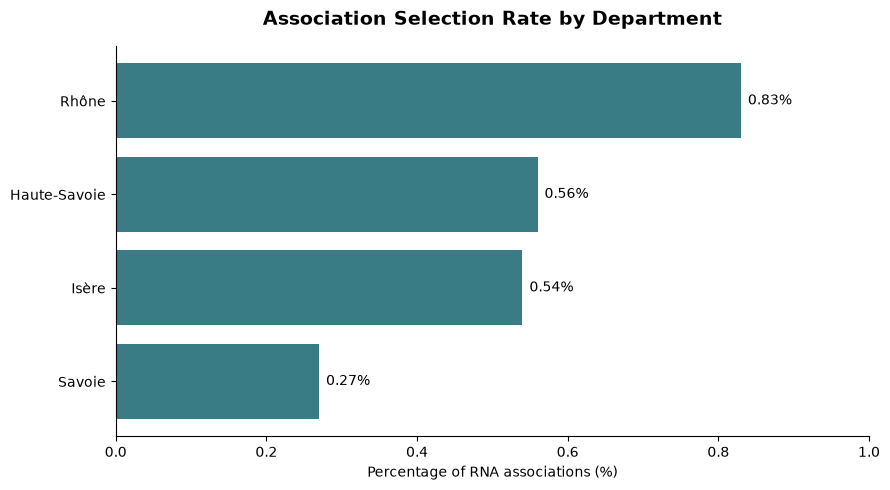

In [71]:
# Visualize selection rates by department
plot_data = eda_summary.sort_values("selection_rate")

department_names = {
    "38": "Isère",
    "69": "Rhône",
    "73": "Savoie",
    "74": "Haute-Savoie"
}

labels = plot_data["department"].map(department_names)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    labels,
    plot_data["selection_rate"],
    color="#397C85"
)

ax.bar_label(bars, fmt="%.2f%%", padding=5)

ax.set_title(
    "Association Selection Rate by Department",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Percentage of RNA associations (%)")
ax.set_xlim(0, 1.0)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### Association Selection Rate by Department

The selection rate represents the percentage of associations matching our study criteria among all RNA associations registered in each department.

The Rhône has the highest rate (0.83%), followed by Haute-Savoie (0.56%), Isère (0.54%), and Savoie (0.27%).

These differences suggest that our selected themes are not equally represented across departments.

However, this indicator does not measure actual service availability or unmet needs. Further analysis of population density and geographic distribution is needed.

### 3.2 Association Density by Population

To compare departments fairly, we use official population data from INSEE.

**Data source:** INSEE, Legal Populations 2023  
**Effective date:** January 1, 2026  
**Indicator:** Municipal population by department

Population figures for the four departments were manually extracted from the official INSEE table and stored in a Python dictionary.

**Source:** https://www.insee.fr/fr/statistiques/8680659

Association density is calculated as the number of selected associations per 100,000 inhabitants.

In [72]:
# INSEE municipal population, reference year 2023
# Source: https://www.insee.fr/fr/statistiques/8680659

population_2023 = {
    "38": 1298990,  # Isère
    "69": 1914667,  # Rhône
    "73": 448226,   # Savoie
    "74": 861158    # Haute-Savoie
}

# Add population data to our EDA summary
eda_summary["population"] = eda_summary["department"].map(population_2023)

# Calculate selected associations per 100,000 inhabitants
eda_summary["density_100k"] = (
    eda_summary["selected"] / eda_summary["population"] * 100000
).round(2)

display(eda_summary)

,department,selected,rna_total,selection_rate,population,density_100k
0,38,240,44208,0.54,1298990,18.48
1,69,564,67657,0.83,1914667,29.46
2,73,42,15483,0.27,448226,9.37
3,74,135,24010,0.56,861158,15.68


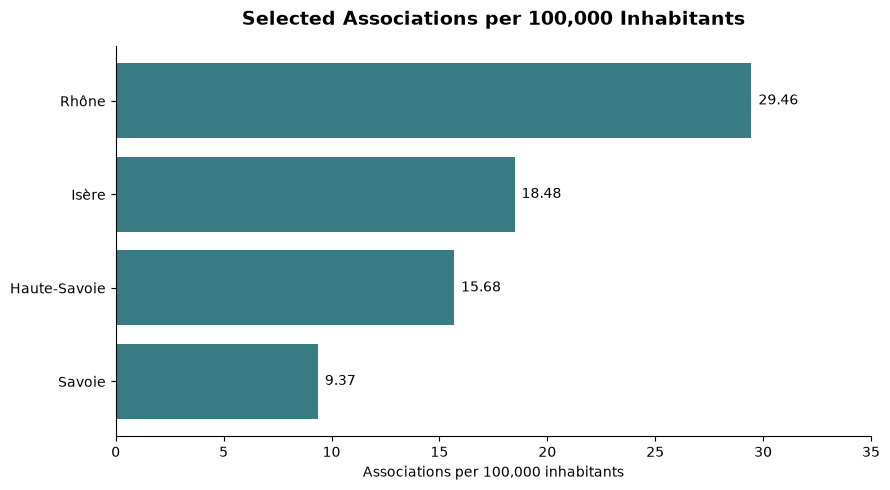

In [73]:
# Sort departments by association density
plot_data = eda_summary.sort_values("density_100k")

labels = plot_data["department"].map(department_names)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    labels,
    plot_data["density_100k"],
    color="#397C85"
)

ax.bar_label(bars, fmt="%.2f", padding=5)

ax.set_title(
    "Selected Associations per 100,000 Inhabitants",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Associations per 100,000 inhabitants")
ax.set_xlim(0, 35)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [74]:
# Count associations by theme and department
theme_columns = [
    "VSS_VIF",
    "WOMEN_EQUALITY",
    "LGBTQIA",
    "DISCRIMINATION"
]

theme_by_department = (
    df_associations
    .groupby("department")[theme_columns]
    .sum()
    .astype(int)
)

display(theme_by_department)

,VSS_VIF,WOMEN_EQUALITY,LGBTQIA,DISCRIMINATION
department,,,,
38,50,133,21,83
69,105,335,99,151
73,12,27,4,10
74,32,90,16,21


In [75]:
# Calculate the percentage of associations in each theme
theme_percentages = (
    theme_by_department
    .div(eda_summary.set_index("department")["selected"], axis=0)
    * 100
).round(1)

display(theme_percentages)

,VSS_VIF,WOMEN_EQUALITY,LGBTQIA,DISCRIMINATION
department,,,,
38,20.8,55.4,8.8,34.6
69,18.6,59.4,17.6,26.8
73,28.6,64.3,9.5,23.8
74,23.7,66.7,11.9,15.6


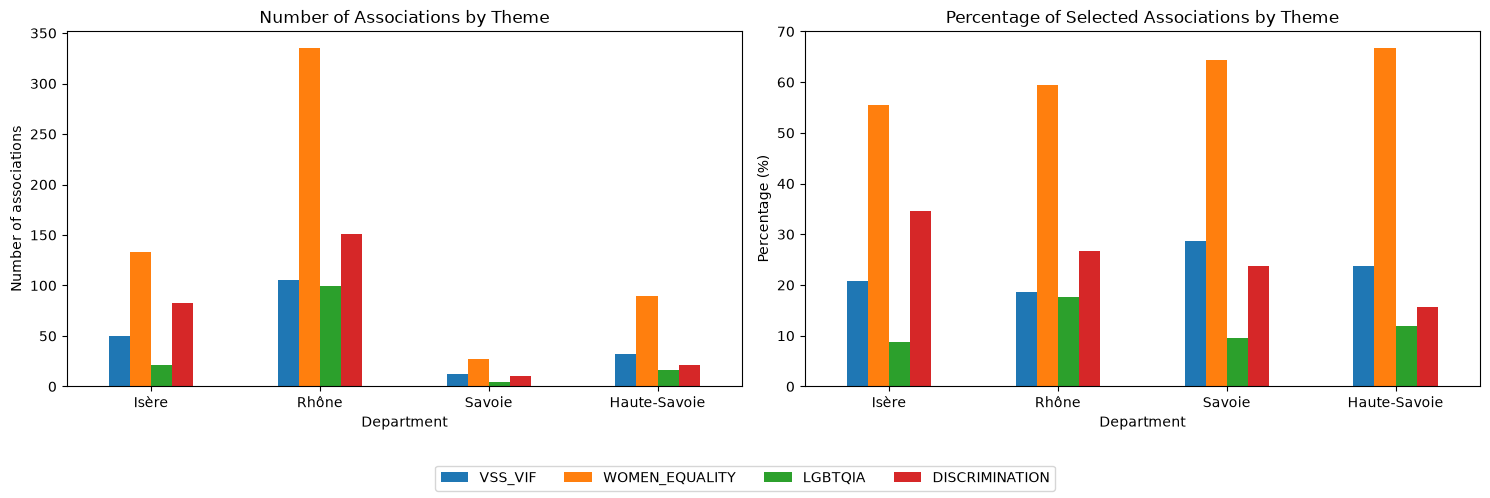

In [76]:
# Compare the number and percentage of associations by theme

counts = theme_by_department.rename(index=department_names)
percentages = theme_percentages.rename(index=department_names)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Number of associations
counts.plot(kind="bar", ax=axes[0], legend=False)

axes[0].set_title("Number of Associations by Theme")
axes[0].set_xlabel("Department")
axes[0].set_ylabel("Number of associations")
axes[0].tick_params(axis="x", rotation=0)

# Percentage of associations
percentages.plot(kind="bar", ax=axes[1], legend=False)

axes[1].set_title("Percentage of Selected Associations by Theme")
axes[1].set_xlabel("Department")
axes[1].set_ylabel("Percentage (%)")
axes[1].tick_params(axis="x", rotation=0)

# One legend for both charts
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4)

plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()

### Key Findings: Thematic Distribution

The Rhône has the highest number of selected associations across all four themes.

However, the percentage analysis reveals different thematic profiles. Savoie has the highest proportion of associations classified as VSS/VIF (28.6%), while Haute-Savoie has the highest proportion in Women's Rights & Equality (66.7%).

These results describe the declared missions of selected associations, not the availability of specialized services.

As associations can belong to multiple themes, categories are not mutually exclusive.


In [77]:
# Check geographic data
geo_columns = [
    "department",
    "adrs_libcommune",
    "adrs_codeinsee",
    "adrs_codepostal"
]

print(df_associations[geo_columns].isna().sum())

display(df_associations[geo_columns].head(10))

department         0
adrs_libcommune    0
adrs_codeinsee     0
adrs_codepostal    0
dtype: int64


,department,adrs_libcommune,adrs_codeinsee,adrs_codepostal
0,38,Grenoble,38185,38100.0
1,38,Grenoble,38185,38100.0
2,38,Clelles en Trièves,38113,38930.0
3,38,Grenoble,38185,38000.0
4,38,Fontaine,38169,38600.0
5,38,Grenoble,38185,38000.0
6,38,Saint-Martin-d'Hères,38421,38400.0
7,38,Grenoble,38185,38000.0
8,38,Fontaine,38169,38600.0
9,38,Grenoble,38185,38100.0


In [78]:
# Count selected associations by municipality
associations_by_city = (
    df_associations
    .groupby(["department", "adrs_codeinsee", "adrs_libcommune"])
    .size()
    .reset_index(name="association_count")
    .sort_values("association_count", ascending=False)
)

display(associations_by_city.head(15))

,department,adrs_codeinsee,adrs_libcommune,association_count
22,38,38185,Grenoble,87
161,69,69266,Villeurbanne,64
206,69,69387,Lyon,37
185,69,69381,Lyon,36
193,69,69383,Lyon,35
242,74,74010,Annecy,33
212,69,69389,Lyon,19
210,69,69388,Lyon,19
207,69,69387,Lyon 7,19
156,69,69259,Vénissieux,18


In [79]:
# Explore selected associations in Bron
bron_associations = df_associations[
    df_associations["adrs_codeinsee"].astype(str) == "69029"
]

display(
    bron_associations[
        ["titre", "objet", "VSS_VIF", "WOMEN_EQUALITY",
         "LGBTQIA", "DISCRIMINATION"]
    ]
)

,titre,objet,VSS_VIF,WOMEN_EQUALITY,LGBTQIA,DISCRIMINATION
315,PLATEFORME COJEPIENNE DE LYON,Participer au développement de la ville de Lyo...,False,False,False,True
346,ASSOCIATION FRANCO-TUNISIENNE,Promouvoir l'entente entre les differentes com...,False,False,False,True
360,ASSOCIATION DES FEMMES DE BRON PARILLY,Ecoute des meres de famille,False,True,False,False
363,AMICALE DRAGON 69,Resserer les liens d'amities entre les differe...,False,True,False,False
380,GROUPE D'ETUDES SUR LES SEXISMES (GES),produire et communiquer de l'information sur l...,False,True,False,False
443,ASSOCIATION LGBT DE LYON 2 - L'ASSOCIATION ÉTU...,accueillir et soutenir les actuel-le-s et anci...,False,False,True,True
463,OLYMPE,"promouvoir, à partir d'une approche genre, l'é...",False,True,False,True
521,JE SOUTIENS AÏSSATOU,"fédérer, organiser l'aide financière, matériel...",False,False,False,False
529,"ASSOCIATION RHÔNALPINE POUR LE DÉVELOPPEMENT, ...",aider au développement de la scolarisation des...,True,False,False,False
530,ASSOCIATION FEMMES BATTANTES INTERNATIONALES D...,favoriser les contacts et agrandir le cercle d...,False,True,False,False


In [80]:
# Associations classified only as discrimination
only_discrimination = df_associations[
    (df_associations["DISCRIMINATION"]) &
    (~df_associations["VSS_VIF"]) &
    (~df_associations["WOMEN_EQUALITY"]) &
    (~df_associations["LGBTQIA"])
]

print("Discrimination only:", len(only_discrimination))
display(only_discrimination[["titre", "objet"]].head(15))

Discrimination only: 117


,titre,objet
0,CENTRE D'INFORMATION INTER PEUPLES C.I.I.P.,Développer l'information sur les problèmes int...
14,FEDERATION DES ALPAGES DE L'ISERE,cette association contribue à la définition et...
16,CLUB 41 DE GRENOBLE N°229 DE LA 10EME REGION,rassembler par cooptation sans distinction de ...
22,MOUVEMENT CONTRE LE RACISME ET POUR L'AMITIE E...,"lutter contre le racisme, c'est-à-dire toutes ..."
25,ER,"venir en aide, sur le plan médical, psychologi..."
26,DEGRES DE TOLERANCE,promouvoir le dialogue et la réflexion autour ...
28,ASSOCIATION FRANCO-ALGERIENNE DE L'ISERE (A.F....,"favoriser, développer et renforcer l'amitié et..."
37,"UNION DES ETUDIANTS JUIFS DE FRANCE, SECTION G...",représenter les étudiants dans la vie universi...
41,SOS RACISME GRENOBLE,"de faire, entreprendre, faire entreprendre tou..."
42,LE CRI,réflexion et propositions sur l'intégration de...


In [81]:
# Count associations classified only as discrimination
print("Associations to exclude:", len(only_discrimination))

print(
    "Remaining associations:",
    len(df_associations) - len(only_discrimination)
)

Associations to exclude: 117
Remaining associations: 864


In [83]:
# Keep associations linked to our three main themes
main_themes = ["VSS_VIF", "WOMEN_EQUALITY", "LGBTQIA"]

df_associations_clean = df_associations[
    df_associations[main_themes].any(axis=1)
].copy()

print("Remaining associations:", len(df_associations_clean))


Remaining associations: 828


In [84]:
# Associations classified only as Women's Equality
only_women = df_associations_clean[
    (df_associations_clean["WOMEN_EQUALITY"]) &
    (~df_associations_clean["VSS_VIF"]) &
    (~df_associations_clean["LGBTQIA"])
]

print("Women's Equality only:", len(only_women))

display(
    only_women[
        ["titre", "objet", "objet_social1", "objet_social2"]
    ].head(20)
)

Women's Equality only: 498


,titre,objet,objet_social1,objet_social2
1,SOLIDARITE FEMMES GRENOBLE - ISERE,accueil et accompagnement des femmes et famill...,3020,3000.0
9,"FEMMES DICI, FEMMES D'AFRIQUE (F.I.F.A.)",valorisation de la femme africaine dans les so...,3020,3040.0
11,HABITAT ET HUMANISME ISERE,en partenariat avec les différents acteurs du ...,14050,0.0
12,"MOUVEMENT FRANCAIS POUR LE PLANNING FAMILIAL, ...",lutter pour construire une société dégalité e...,19000,0.0
15,COMITE NI PUTES NI SOUMISES DE GRENOBLE,entreprendre et faire entreprendre toute actio...,3020,0.0
18,VOREPPE TWIRLING,"organisation, développement et promotion du tw...",11105,0.0
20,SOROPTIMIST INTERNATIONAL DE GRENOBLE 2000,organisation mondiale des femmes engagées dans...,3020,0.0
23,"ASSOCIATION FILLE-MERE, DEBOUT ! (A.F, D !)",en France : faire connaître l'Afrique Francoph...,3020,14040.0
33,VOIX DE FEMMES,"favoriser, développer et renforcer les liens d...",14050,0.0
35,GROUPE D'ENTRAIDE ET DE REFLEXION DES FEMMES A...,"entraide, solidarité et réflexion, dans un esp...",14050,20020.0


In [85]:
# Check how associations were classified as Women's Equality

women_text = (
    only_women["titre"].fillna("") + " " +
    only_women["objet"].fillna("")
)

women_by_keywords = women_text.str.contains(
    equality_keywords, case=False, na=False, regex=True
)

women_by_waldec = (
    only_women["objet_social1"].isin([3020, 14050]) |
    only_women["objet_social2"].isin([3020, 14050])
)

print("Keywords:", women_by_keywords.sum())
print("WALDEC codes:", women_by_waldec.sum())
print("Both:", (women_by_keywords & women_by_waldec).sum())

Keywords: 158
WALDEC codes: 384
Both: 44


In [86]:
# Check WALDEC codes for associations without keyword matches
waldec_only = only_women[
    women_by_waldec & ~women_by_keywords
]

print("Code 3020:", (
    (waldec_only["objet_social1"] == 3020) |
    (waldec_only["objet_social2"] == 3020)
).sum())

print("Code 14050:", (
    (waldec_only["objet_social1"] == 14050) |
    (waldec_only["objet_social2"] == 14050)
).sum())

Code 3020: 90
Code 14050: 254


In [87]:
# Test selection based on keywords only
text = (
    df_associations["titre"].fillna("") + " " +
    df_associations["objet"].fillna("")
)

keyword_selection = pd.Series(False, index=df_associations.index)

for pattern in [vss_keywords, equality_keywords, lgbt_keywords]:
    keyword_selection |= text.str.contains(
        pattern, case=False, na=False, regex=True
    )

df_keywords_test = df_associations[keyword_selection].copy()

print("Initial selection:", len(df_associations))
print("Keyword selection:", len(df_keywords_test))

Initial selection: 981
Keyword selection: 416


In [88]:
# Check associations excluded by the keyword selection
excluded_associations = df_associations[~keyword_selection]

print("Excluded associations:", len(excluded_associations))

display(
    excluded_associations[
        ["titre", "objet", "objet_social1", "objet_social2"]
    ].sample(20, random_state=42)
)

Excluded associations: 565


,titre,objet,objet_social1,objet_social2
940,EN MEMOIRE DE GREGORY MERCIER ASSASSINE,contribuer à identifier l'assassin de Grégory ...,4030,3025.0
918,GLOW BIKE,l'association GLOW BIKE a pour objet de promou...,11180,14050.0
334,LES 2L RONDS,développer des projets et actions humanitaires...,14050,6100.0
919,FEMMES DIRIGEANTES DE SPORT,créer et maintenir le lien entre les femmes di...,14050,11000.0
847,ASSOCIATION DES TUNISIENS EN FRANCE HAUTE-SAVOIE,"regrouper les Tunisiens, les originaires du Ma...",14040,0.0
454,L4 4L DONNE DES ELLES,apporter des fournitures scolaires et sportive...,14050,0.0
351,AMICALE DES ANCIENS SAPEURS POMPIERS VOLONTAIR...,Solidarite entre anciens sapeurs pompiers,14050,0.0
864,FDE - FAISEURS D'EXPLOITS INTERNATIONAL,groupe de femmes soucieuses de valeurs familia...,14050,5000.0
621,AU SERVICE D'AUTRUI (A.S.A.),l'association AU SERVICE D'AUTRUI (A.S.A) réun...,14035,3040.0
320,BUREAU DE L'AMICALE DES SAPEURS POMPIERS DE TO...,Organisation des fetes locales,14000,14050.0


In [89]:
# Keywords based on declared association missions

theme_keywords = {
    "VSS_VIF": (
        r"violences? (?:conjugales?|intrafamiliales?|sexistes?|sexuelles?)"
        r"|violences? faites? aux femmes"
        r"|féminicides?"
        r"|contrôle coercitif"
        r"|agressions? sexuelles?"
        r"|harcèlement sexuel"
        r"|inceste"
        r"|mutilations? sexuelles?"
        r"|mariages? forcés?"
        r"|exploitation sexuelle"
        r"|victimes? de violences?"
    ),

    "WOMEN_EQUALITY": (
        r"droits? des femmes"
        r"|égalité (?:femmes[- ]hommes|hommes[- ]femmes|des sexes)"
        r"|égalité entre (?:les femmes et les hommes|les hommes et les femmes)"
        r"|parité (?:femmes[- ]hommes|hommes[- ]femmes)"
        r"|féminis(?:me|tes?)"
        r"|sexisme"
        r"|émancipation des femmes"
        r"|autonomisation des femmes"
        r"|empowerment féminin"
        r"|condition féminine"
        r"|santé des femmes"
        r"|droits? (?:reproductifs?|sexuels?)"
        r"|accès des femmes aux droits"
    ),

    "LGBTQIA": (
        r"lgbt(?:qia?)?\+?"
        r"|homosexualité"
        r"|homophobie"
        r"|lesbophobie"
        r"|transphobie"
        r"|transidentité"
        r"|transgenres?"
        r"|orientation sexuelle"
        r"|identité de genre"
    )
}

In [90]:
# Combine the four original department datasets
df_rna_all = pd.concat(
    [df_rna_38, df_rna_69, df_rna_73, df_rna_74],
    ignore_index=True
)

# Search for keywords in declared missions
text = df_rna_all["objet"].fillna("")

for theme, pattern in theme_keywords.items():
    df_rna_all[theme] = text.str.contains(
        pattern, case=False, na=False, regex=True
    )

# Keep associations matching at least one theme
theme_columns = list(theme_keywords.keys())

df_keywords_new = df_rna_all[
    df_rna_all[theme_columns].any(axis=1)
].copy()

print("Total RNA associations:", len(df_rna_all))
print("Selected associations:", len(df_keywords_new))

Total RNA associations: 151358
Selected associations: 583


In [91]:
# Review a sample of selected associations
sample = df_keywords_new.sample(15, random_state=42)

for _, row in sample.iterrows():
    print("\nAssociation:", row["titre"])
    print("Mission:", row["objet"])
    print("Themes:", [
        theme for theme in theme_columns if row[theme]
    ])
    print("-" * 60)


Association: ESTEEM FOR CHANGE
Mission: promouvoir et soutenir les filles et les femmes dans les métiers des STEM (sciences, technologie, ingénierie, mathématiques) et du numérique, par l'accompagnement et l'éducation, pour participer à l'égalité entre les femmes et les hommes dans ces secteurs
Themes: ['WOMEN_EQUALITY']
------------------------------------------------------------

Association: LES TÉTONS FRIPONS - CABARET BURLESQUE
Mission: promouvoir la pratique New-burlesque par l'organisation
et/ou la participation à des spectacles, des manifestations, des ateliers créatifs ; l'objectif principal de l'ensemble des actions menées au nom de l'association est de participer à l'amélioration de la condition féminine dans la société, et de la santé des femmes
Themes: ['WOMEN_EQUALITY']
------------------------------------------------------------

Association: GRAINES D'EGALITÉ
Mission: promouvoir des relations égalitaires et respectueuses pour prévenir les discriminations et les violenc

In [92]:
# Check postal codes in the selected associations
postal_codes = (
    df_keywords_new["adrs_codepostal"]
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
)

valid_departments = ("38", "69", "73", "74")

geo_match = postal_codes.str.startswith(valid_departments)

print("Selected associations:", len(df_keywords_new))
print("Within geographic scope:", geo_match.sum())
print("Outside geographic scope:", (~geo_match).sum())

Selected associations: 583
Within geographic scope: 568
Outside geographic scope: 15


In [93]:
# Keep associations within the four departments
df_associations_clean = df_keywords_new.loc[geo_match].copy()

# Add the department column
df_associations_clean["department"] = postal_codes.loc[geo_match].str[:2]

print("Final selection:", len(df_associations_clean))
print(df_associations_clean["department"].value_counts().sort_index())

Final selection: 568
department
38    116
69    337
73     29
74     86
Name: count, dtype: int64


In [94]:
# Check duplicate association IDs
print("Total associations:", len(df_associations_clean))
print("Unique RNA IDs:", df_associations_clean["id"].nunique())
print("Duplicate IDs:", df_associations_clean["id"].duplicated().sum())

Total associations: 568
Unique RNA IDs: 568
Duplicate IDs: 0
